In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.optimize import minimize
from scipy.special import erf
from scipy.stats import chi2

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True})
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
FIGURE_DIR =  PROJECT_ROOT / "figures"
print(PROJECT_ROOT)
print(FIGURE_DIR)

c:\Users\nickk\OneDrive\Desktop\CompPhysGrad\ProjectI\project1-nkoval-wm
c:\Users\nickk\OneDrive\Desktop\CompPhysGrad\ProjectI\project1-nkoval-wm\figures


In [2]:
if Path.cwd().name == "notebooks":
    repo_root = Path.cwd().parent
else:
    repo_root = Path.cwd()

data_dir = repo_root / "data" / "raw"
data_dir.mkdir(parents=True, exist_ok=True)
data_path = data_dir / "Ymumu.csv"

candidate_urls = [
    "https://opendata.cern.ch/record/5206/files/Ymumu.csv?download=1",
    "https://opendata.cern.ch/record/cms-5206/files/Ymumu.csv?download=1",
    "http://opendata.cern.ch/record/5206/files/Ymumu.csv?download=1",
    "http://cern.ch/opendata/record/5206/files/Ymumu.csv",
]

def load_upsilon_data(path=data_path):
    if path.exists():
        return pd.read_csv(path), str(path)

    errors = []
    for url in candidate_urls:
        try:
            table = pd.read_csv(url)
            if len(table) > 1000:
                table.to_csv(path, index=False)
                return table, url
        except Exception as exc:
            errors.append(f"{url}: {type(exc).__name__}: {exc}")

    raise FileNotFoundError(
        "Could not load the CMS Upsilon CSV automatically. Download it from "
        "https://opendata.cern.ch/record/cms-5206 and save it as "
        f"{path}. Tried:\n" + "\n".join(errors)
    )

events, source = load_upsilon_data()
print(f"Loaded {len(events):,} events from {source}")
events.head()

Loaded 20,000 events from c:\Users\nickk\OneDrive\Desktop\CompPhysGrad\ProjectI\project1-nkoval-wm\data\raw\Ymumu.csv


,Run,Event,type1,E1,px1,py1,pz1,pt1,eta1,phi1,Q1,type2,E2,px2,py2,pz2,pt2,eta2,phi2,Q2
0,165617,75100943,G,6.2039,-4.2666,0.4565,-4.4793,4.2910,-0.9121,3.0350,-1,G,9.6690,7.2740,-2.8211,-5.7104,7.8019,-0.6786,-0.3700,1
1,165617,75587682,G,19.2892,-4.2121,-0.6516,18.8121,4.2622,2.1905,-2.9881,-1,G,9.8244,4.3439,-0.4735,8.7985,4.3697,1.4497,-0.1086,1
2,165617,75167029,G,9.7583,2.3903,-3.7824,8.6715,4.4744,1.4156,-1.0072,-1,G,13.5684,-3.3975,5.1910,12.0665,6.2039,1.4187,2.1503,1
3,165617,75281957,G,9.6365,1.6516,-5.4313,7.7862,5.6769,1.1213,-1.2756,1,G,7.0263,-1.6449,4.4418,5.1887,4.7366,0.9473,1.9255,-1
4,165617,75393376,G,6.0112,3.3614,2.8883,4.0598,4.4318,0.8208,0.7098,-1,G,7.7557,-5.0416,-3.0126,5.0642,5.8731,0.7806,-2.6030,1


In [3]:
required_columns = ["E1", "px1", "py1", "pz1", "E2", "px2", "py2", "pz2"]
missing_columns = [column for column in required_columns if column not in events.columns]
if missing_columns:
    raise ValueError(f"Missing required four-vector columns: {missing_columns}")

total_energy = events["E1"] + events["E2"]
total_px = events["px1"] + events["px2"]
total_py = events["py1"] + events["py2"]
total_pz = events["pz1"] + events["pz2"]

mass_squared = total_energy**2 - total_px**2 - total_py**2 - total_pz**2
events["M_recomputed"] = np.sqrt(np.clip(mass_squared, 0.0, None))
events["dimuon_pt"] = np.sqrt(total_px**2 + total_py**2)

events[["E1", "px1", "py1", "pz1", "E2", "px2", "py2", "pz2", "M_recomputed", "dimuon_pt"]].head()

,E1,px1,py1,pz1,E2,px2,py2,pz2,M_recomputed,dimuon_pt
0,6.2039,-4.2666,0.4565,-4.4793,9.6690,7.2740,-2.8211,-5.7104,11.553492,3.825675
1,19.2892,-4.2121,-0.6516,18.8121,9.8244,4.3439,-0.4735,8.7985,9.163692,1.132794
2,9.7583,2.3903,-3.7824,8.6715,13.5684,-3.3975,5.1910,12.0665,10.539055,1.731648
3,9.6365,1.6516,-5.4313,7.7862,7.0263,-1.6449,4.4418,5.1887,10.407772,0.989523
4,6.0112,3.3614,2.8883,4.0598,7.7557,-5.0416,-3.0126,5.0642,10.170626,1.684792


In [4]:
MASS_RANGE = (8.0, 12.0)

analysis_data = events.loc[
    events["M_recomputed"].between(MASS_RANGE[0], MASS_RANGE[1], inclusive="both")
].copy()


def normal_cdf(x, mean, sigma):
    """Evaluate the Gaussian cumulative distribution function."""
    return 0.5 * (1.0 + erf((x - mean) / (np.sqrt(2.0) * sigma)))


def truncated_gaussian_pdf(x, mean, sigma, lower, upper):
    """Gaussian PDF renormalized to integrate to one inside [lower, upper]."""
    normalization = normal_cdf(upper, mean, sigma) - normal_cdf(lower, mean, sigma)
    density = np.exp(-0.5 * ((x - mean) / sigma) ** 2) / (
        np.sqrt(2.0 * np.pi) * sigma
    )
    return density / normalization
# Note this in the ReadMe section. This is something ben curcio used in his research
# and it makes things fit very well. I used AI to determine how this was implemented.

def truncated_chebyshev_pdf(x, coefficient1, coefficient2, lower, upper):
    """Second-order Chebyshev PDF normalized inside [lower, upper]."""

    polynomial = np.polynomial.Chebyshev(
        [1.0, coefficient1, coefficient2],
        domain=[lower, upper],
    )

    density = polynomial(x)

    integral = polynomial.integ()
    normalization = integral(upper) - integral(lower)

    return density / normalization


def unpack_full_parameters(transformed_parameters):
    """Convert optimizer parameters into physical parameters with positive yields and widths."""

    log_signal1_yield, log_signal2_yield, log_signal3_yield, log_signal4_yield, \
    log_background_yield, mass1_mean, log_mass1_sigma, \
    mass2_mean, log_mass2_sigma, mass3_mean, log_mass3_sigma, mass4_mean, log_mass4_sigma, \
    background_cheb1, background_cheb2 = transformed_parameters

    return pd.Series(
        {
            "signal_yield1": np.exp(log_signal1_yield),
            "signal_yield2": np.exp(log_signal2_yield),
            "signal_yield3": np.exp(log_signal3_yield),
            "signal_yield4": np.exp(log_signal4_yield),
            "background_yield": np.exp(log_background_yield),

            "mass_mean1_GeV": mass1_mean,
            "mass_sigma1_GeV": np.exp(log_mass1_sigma),

            "mass_mean2_GeV": mass2_mean,
            "mass_sigma2_GeV": np.exp(log_mass2_sigma),

            "mass_mean3_GeV": mass3_mean,
            "mass_sigma3_GeV": np.exp(log_mass3_sigma),

            "mass_mean4_GeV": mass4_mean,
            "mass_sigma4_GeV": np.exp(log_mass4_sigma),

            "background_cheb1": background_cheb1,
            "background_cheb2": background_cheb2,
        }
    )


def signal_density1(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean1_GeV"],
        parameters["mass_sigma1_GeV"],
        *MASS_RANGE,
    )


def signal_density2(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean2_GeV"],
        parameters["mass_sigma2_GeV"],
        *MASS_RANGE,
    )


def signal_density3(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean3_GeV"],
        parameters["mass_sigma3_GeV"],
        *MASS_RANGE,
    )

def signal_density4(data, parameters):
    """Evaluate the unit-normalized signal mass density for every event."""
    return truncated_gaussian_pdf(
        data["M_recomputed"],
        parameters["mass_mean4_GeV"],
        parameters["mass_sigma4_GeV"],
        *MASS_RANGE,
    )


def background_density(data, parameters):
    """Evaluate the unit-normalized background mass density for every event."""

    return truncated_chebyshev_pdf(
        data["M_recomputed"],
        parameters["background_cheb1"],
        parameters["background_cheb2"],
        *MASS_RANGE,
    )


def full_intensity(data, transformed_parameters):
    """Combine signal and background densities into the event intensity I(m; theta)."""

    parameters = unpack_full_parameters(transformed_parameters)

    return (
        parameters["signal_yield1"] * signal_density1(data, parameters)
        + parameters["signal_yield2"] * signal_density2(data, parameters)
        + parameters["signal_yield3"] * signal_density3(data, parameters)
        + parameters["signal_yield4"] * signal_density4(data, parameters)
        + parameters["background_yield"] * background_density(data, parameters)
    )


def negative_log_likelihood_full(transformed_parameters, data=analysis_data):
    """Return the extended negative log-likelihood for the signal-plus-background model."""

    parameters = unpack_full_parameters(transformed_parameters)

    # Penalize parameter values outside the intended physical/model range.
    if not (MASS_RANGE[0] < parameters["mass_mean1_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean2_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean3_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean4_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma1_GeV"] < 0.30):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma2_GeV"] < 0.30):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma3_GeV"] < 0.30):
        return 1.0e30
    
    if not (0.005 < parameters["mass_sigma4_GeV"] < 0.30):
        return 1.0e30

    # The log-likelihood is only defined for positive, finite event intensities.
    event_intensity = full_intensity(data, transformed_parameters)

    if np.any(event_intensity <= 0.0) or np.any(~np.isfinite(event_intensity)):
        return 1.0e30

    # N_model is the integral of I(m; theta) over the fitted mass range.
    n_model = (
        parameters["signal_yield1"]
        + parameters["signal_yield2"]
        + parameters["signal_yield3"]
        + parameters["signal_yield4"]
        + parameters["background_yield"]
    )

    return n_model - np.sum(np.log(event_intensity))


initial_full_parameters = np.array([
    np.log(2000.0),   # Upsilon(1S) yield
    np.log(1000.0),    # Upsilon(2S) yield
    np.log(800.0),    # Upsilon(3S) yield
    np.log(800.0),    # Upsilon(4S) yield
    np.log(16500.0),   # background yield

    9.4604,           # Upsilon(1S) mass mean
    np.log(0.075),    # Upsilon(1S) detector width

    10.0234,          # Upsilon(2S) mass mean
    np.log(0.085),    # Upsilon(2S) detector width

    10.3551,          # Upsilon(3S) mass mean
    np.log(0.090),    # Upsilon(3S) detector width

    10.5794,          # Upsilon(4S) mass mean
    np.log(0.090),    # Upsilon(4S) detector width

    0.65,              # first-order Chebyshev coefficient
    0.0
])


full_parameter_bounds = [
    (np.log(1.0), np.log(10000.0)),    # Upsilon(1S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(2S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(3S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(4S) yield
    (np.log(1.0), np.log(20000.0)),    # background yield

    (9.40, 9.52),                       # Upsilon(1S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(1S) sigma

    (9.96, 10.08),                      # Upsilon(2S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(2S) sigma

    (10.30, 10.38),                     # Upsilon(3S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(3S) sigma

    (10.4, 10.6),                     # Upsilon(3S) mean
    (np.log(0.04), np.log(0.30)),      # Upsilon(3S) sigma

    (0.0, 0.8),
    (-0.25, 0.25),
]


full_fit_result = minimize(
    negative_log_likelihood_full,
    x0=initial_full_parameters,
    method="L-BFGS-B",
    bounds=full_parameter_bounds,
    options={"maxiter": 20000, "ftol": 1.0e-9},
)


full_fit_parameters = unpack_full_parameters(full_fit_result.x)

print("fit success:", full_fit_result.success)
print("negative log-likelihood:", full_fit_result.fun)

full_fit_parameters.to_frame("estimate")

fit success: True
negative log-likelihood: -152546.39929519413


,estimate
signal_yield1,2268.371628
signal_yield2,856.629151
signal_yield3,494.618808
signal_yield4,160.912764
background_yield,16219.928768
mass_mean1_GeV,9.445949
mass_sigma1_GeV,0.091242
mass_mean2_GeV,10.014236
mass_sigma2_GeV,0.104237
mass_mean3_GeV,10.343866


- Im a little suprised by where the fit wants to put the fourth peak. we expect Upsilon(4S) to be at 10.579 GeV

In [5]:
def mass_projection_density1(mass_values, parameters):
    """Evaluate the fitted mass intensity on a grid for plotting."""

    mass_frame = pd.DataFrame({"M_recomputed": mass_values})

    signal_mass1 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean1_GeV"],
        parameters["mass_sigma1_GeV"],
        *MASS_RANGE,
    )
    return (
        parameters["signal_yield1"] * signal_mass1)

def mass_projection_density2(mass_values, parameters):
    """Evaluate the fitted mass intensity on a grid for plotting."""

    mass_frame = pd.DataFrame({"M_recomputed": mass_values})

    signal_mass2 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean2_GeV"],
        parameters["mass_sigma2_GeV"],
        *MASS_RANGE,
    )
    return (
        parameters["signal_yield2"] * signal_mass2)

def mass_projection_density3(mass_values, parameters):
    """Evaluate the fitted mass intensity on a grid for plotting."""

    mass_frame = pd.DataFrame({"M_recomputed": mass_values})

    signal_mass3 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean3_GeV"],
        parameters["mass_sigma3_GeV"],
        *MASS_RANGE,
    )
    return (
        parameters["signal_yield3"] * signal_mass3)

def mass_projection_density4(mass_values, parameters):
    """Evaluate the fitted mass intensity on a grid for plotting."""

    mass_frame = pd.DataFrame({"M_recomputed": mass_values})

    signal_mass4 = truncated_gaussian_pdf(
        mass_frame["M_recomputed"],
        parameters["mass_mean4_GeV"],
        parameters["mass_sigma4_GeV"],
        *MASS_RANGE,
    )
    return (
        parameters["signal_yield4"] * signal_mass4)

def mass_projection_density_background(mass_values, parameters):

    mass_frame = pd.DataFrame({"M_recomputed": mass_values})
    background_mass = truncated_chebyshev_pdf(
        mass_frame["M_recomputed"],
        parameters["background_cheb1"],
        parameters["background_cheb2"],
        *MASS_RANGE,
    )
    return (
        parameters["background_yield"] * background_mass)


# Evaluate the fitted intensity on a dense mass grid.
mass_grid = pd.DataFrame(
    {"M_recomputed": np.linspace(*MASS_RANGE, 2000)}
)

mass_grid["fit1_events_per_GeV"] = mass_projection_density1(
    mass_grid["M_recomputed"],
    full_fit_parameters,
)
mass_grid["fit2_events_per_GeV"] = mass_projection_density2(
    mass_grid["M_recomputed"],
    full_fit_parameters,
)
mass_grid["fit3_events_per_GeV"] = mass_projection_density3(
    mass_grid["M_recomputed"],
    full_fit_parameters,
)
mass_grid["fit4_events_per_GeV"] = mass_projection_density4(
    mass_grid["M_recomputed"],
    full_fit_parameters,
)
mass_grid["fit_back_events_per_GeV"] = mass_projection_density_background(
    mass_grid["M_recomputed"],
    full_fit_parameters,
)

c1 = 0.5204566972944514
c2 = -0.20284652679357684


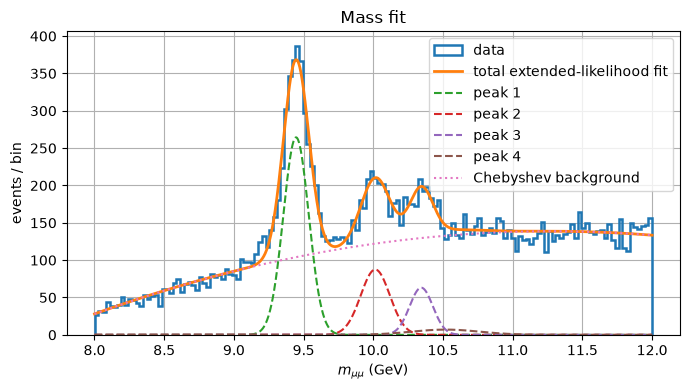

In [6]:
# Evaluate each fitted component separately on the mass grid.

mass_grid["fit1_events_per_GeV"] = (
    full_fit_parameters["signal_yield1"]
    * truncated_gaussian_pdf(
        mass_grid["M_recomputed"],
        full_fit_parameters["mass_mean1_GeV"],
        full_fit_parameters["mass_sigma1_GeV"],
        *MASS_RANGE,
    )
)

mass_grid["fit2_events_per_GeV"] = (
    full_fit_parameters["signal_yield2"]
    * truncated_gaussian_pdf(
        mass_grid["M_recomputed"],
        full_fit_parameters["mass_mean2_GeV"],
        full_fit_parameters["mass_sigma2_GeV"],
        *MASS_RANGE,
    )
)

mass_grid["fit3_events_per_GeV"] = (
    full_fit_parameters["signal_yield3"]
    * truncated_gaussian_pdf(
        mass_grid["M_recomputed"],
        full_fit_parameters["mass_mean3_GeV"],
        full_fit_parameters["mass_sigma3_GeV"],
        *MASS_RANGE,
    )
)

mass_grid["fit4_events_per_GeV"] = (
    full_fit_parameters["signal_yield4"]
    * truncated_gaussian_pdf(
        mass_grid["M_recomputed"],
        full_fit_parameters["mass_mean4_GeV"],
        full_fit_parameters["mass_sigma4_GeV"],
        *MASS_RANGE,
    )
)

mass_grid["fit_back_events_per_GeV"] = (
    full_fit_parameters["background_yield"]
    * truncated_chebyshev_pdf(
        mass_grid["M_recomputed"],
        full_fit_parameters["background_cheb1"],
        full_fit_parameters["background_cheb2"],
        *MASS_RANGE,
    )
)

mass_grid["fit_events_per_GeV"] = (
    mass_grid["fit1_events_per_GeV"]
    + mass_grid["fit2_events_per_GeV"]
    + mass_grid["fit3_events_per_GeV"]
    + mass_grid["fit4_events_per_GeV"]
    + mass_grid["fit_back_events_per_GeV"]
)

# Compare the mass projection of the fit with the observed histogram.
fig, ax = plt.subplots(figsize=(7, 4))

mass_counts, mass_edges, _ = ax.hist(
    analysis_data["M_recomputed"],
    bins=150,
    histtype="step",
    lw=1.8,
    label="data",
)

mass_bin_width = mass_edges[1] - mass_edges[0]

# Total fit
ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit_events_per_GeV"] * mass_bin_width,
    lw=2,
    label="total extended-likelihood fit",
)

# Individual peaks.
ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit1_events_per_GeV"] * mass_bin_width,
    "--",
    label="peak 1",
)

ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit2_events_per_GeV"] * mass_bin_width,
    "--",
    label="peak 2",
)

ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit3_events_per_GeV"] * mass_bin_width,
    "--",
    label="peak 3",
)

ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit4_events_per_GeV"] * mass_bin_width,
    "--",
    label="peak 4",
)

# Background.
ax.plot(
    mass_grid["M_recomputed"],
    mass_grid["fit_back_events_per_GeV"] * mass_bin_width,
    ":",
    label="Chebyshev background",
)

ax.set_xlabel(r"$m_{\mu\mu}$ (GeV)")
ax.set_ylabel("events / bin")
ax.set_title("Mass fit")
ax.legend()

fig.tight_layout()
plt.savefig(PROJECT_ROOT / "figures" / "Four_Peak_Mass_Fit.png", dpi=300, bbox_inches="tight")


print("c1 =", full_fit_parameters["background_cheb1"])
print("c2 =", full_fit_parameters["background_cheb2"])

- I plotted all four separately because I wanted to visualize where the optimizer set the fourth peak. From what we know about Upsilon(4S) this peak is not in the correct place, but we'll do a q value test to determine if the extra peak improves the fit. 

In [7]:

def unpack_3peak_parameters(transformed_parameters):
    """Convert optimizer parameters into physical parameters with positive yields and widths."""

    log_signal1_yield, log_signal2_yield, log_signal3_yield, \
    log_background_yield, mass1_mean, log_mass1_sigma, \
    mass2_mean, log_mass2_sigma, mass3_mean, log_mass3_sigma, \
    background_cheb1, background_cheb2 = transformed_parameters

    return pd.Series(
        {
            "signal_yield1": np.exp(log_signal1_yield),
            "signal_yield2": np.exp(log_signal2_yield),
            "signal_yield3": np.exp(log_signal3_yield),
            "background_yield": np.exp(log_background_yield),

            "mass_mean1_GeV": mass1_mean,
            "mass_sigma1_GeV": np.exp(log_mass1_sigma),

            "mass_mean2_GeV": mass2_mean,
            "mass_sigma2_GeV": np.exp(log_mass2_sigma),

            "mass_mean3_GeV": mass3_mean,
            "mass_sigma3_GeV": np.exp(log_mass3_sigma),

            "background_cheb1": background_cheb1,
            "background_cheb2": background_cheb2,
        }
    )

def three_peak_intensity(data, transformed_parameters):
    """Combine signal and background densities into the event intensity I(m; theta)."""

    parameters = unpack_3peak_parameters(transformed_parameters)

    return (
        parameters["signal_yield1"] * signal_density1(data, parameters)
        + parameters["signal_yield2"] * signal_density2(data, parameters)
        + parameters["signal_yield3"] * signal_density3(data, parameters)
        + parameters["background_yield"] * background_density(data, parameters)
    )

def negative_three_peak_log_likelihood(transformed_parameters, data=analysis_data):
    """Return the extended negative log-likelihood for the signal-plus-background model."""

    parameters = unpack_3peak_parameters(transformed_parameters)

    # Penalize parameter values outside the intended physical/model range.
    if not (MASS_RANGE[0] < parameters["mass_mean1_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean2_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (MASS_RANGE[0] < parameters["mass_mean3_GeV"] < MASS_RANGE[1]):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma1_GeV"] < 0.30):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma2_GeV"] < 0.30):
        return 1.0e30

    if not (0.005 < parameters["mass_sigma3_GeV"] < 0.30):
        return 1.0e30

    # The log-likelihood is only defined for positive, finite event intensities.
    three_peak_event_intensity = three_peak_intensity(data, transformed_parameters)

    if np.any(three_peak_event_intensity <= 0.0) or np.any(~np.isfinite(three_peak_event_intensity)):
        return 1.0e30

    # N_model is the integral of I(m; theta) over the fitted mass range.
    n_model = (
        parameters["signal_yield1"]
        + parameters["signal_yield2"]
        + parameters["signal_yield3"]
        + parameters["background_yield"]
    )

    return n_model - np.sum(np.log(three_peak_event_intensity))


initial_three_peak_parameters = np.array([
    np.log(2000.0),   # Upsilon(1S) yield
    np.log(1000.0),    # Upsilon(2S) yield
    np.log(1000.0),    # Upsilon(3S) yield
    np.log(17000.0),   # background yield

    9.4604,           # Upsilon(1S) mass mean
    np.log(0.075),    # Upsilon(1S) detector width

    10.0234,          # Upsilon(2S) mass mean
    np.log(0.085),    # Upsilon(2S) detector width

    10.3551,          # Upsilon(3S) mass mean
    np.log(0.090),    # Upsilon(3S) detector width

    0.65,              # first-order Chebyshev coefficient
    0.0
])


three_peak_parameter_bounds = [
    (np.log(1.0), np.log(10000.0)),    # Upsilon(1S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(2S) yield
    (np.log(1.0), np.log(10000.0)),    # Upsilon(3S) yield
    (np.log(1.0), np.log(20000.0)),    # background yield

    (9.40, 9.52),                       # Upsilon(1S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(1S) sigma

    (9.96, 10.08),                      # Upsilon(2S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(2S) sigma

    (10.30, 10.38),                     # Upsilon(3S) mean
    (np.log(0.04), np.log(0.15)),      # Upsilon(3S) sigma

    (0.0, 0.8),
    (-0.25, 0.25),
]


three_peak_fit_result = minimize(
    negative_three_peak_log_likelihood,
    x0=initial_three_peak_parameters,
    method="L-BFGS-B",
    bounds=three_peak_parameter_bounds,
    options={"maxiter": 20000, "ftol": 1.0e-9},
)

likelihood_ratio_statistic = 2 * (three_peak_fit_result.fun - full_fit_result.fun)
delta_parameters = len(full_fit_result.x)-len(three_peak_fit_result.x)
approximate_p_value = chi2.sf(likelihood_ratio_statistic,delta_parameters)

likelihood_ratio_table = pd.DataFrame([
    {
        "comparison": "three peak vs four peak",
        "q_delta_minus_2_log_L": likelihood_ratio_statistic,
        "delta_parameters": delta_parameters,
        "approximate_p_value": approximate_p_value,
        "caveat": "signal yield is bounded at zero; Wilks approximation is not exact",
    }
])
likelihood_ratio_table

,comparison,q_delta_minus_2_log_L,delta_parameters,approximate_p_value,caveat
0,three peak vs four peak,1.202653,3,0.752368,signal yield is bounded at zero; Wilks approxi...


- This confirms my expectation. The small delta q means that the likelihood imporvement from the fourth peak was nominal while adding in three axtra parameters. the realtively large p value means that assuming the three peak model was correct, obtaining this chi^2 from this data was likely. Thus supporting the case for a three peak fit as opposed to the four peak fit.  